In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

from pyprojroot import here

# Ajout de la racine au sys.path pour rendre les dossiers importables
root_dir = here()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from ann_playground.data import fetch_and_save_dataset

In [2]:
import joblib

clean_data_dir = here("data/clean_data")

df = pd.read_parquet(clean_data_dir / "df.parquet")
X_train_prep = joblib.load(clean_data_dir / "X_train_prep.pkl")
X_test_prep = joblib.load(clean_data_dir / "X_test_prep.pkl")
y_train = joblib.load(clean_data_dir / "y_train.pkl")
y_test = joblib.load(clean_data_dir / "y_test.pkl")

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# Multi-Layer Perceptron : using Keras

- Pour un problème de classification tabulaire à 3 classes avec un nombre de colonnes transformées potentiellement élevé (à cause du One-Hot Encoding des variables catégorielles), une architecture classique à deux couches cachées fonctionne très bien

## 1. Création d'un Multi-Layer Perceptron

In [ ]:
%pip install tensorflow

### 1a. Définition de l'architecture du réseau

Les couches Dropout jouent un rôle crucial de régularisation dans le réseau de neurones.

1. Pendant la phase d'entraînement (fit), chaque couche de Dropout désactive aléatoirement un certain pourcentage de connexions (ou de neurones de la couche précédente) à chaque passage de données (batch). Avec un taux de dropout de 0.3, 30% des neurones sont "éteints" au hasard à chaque étape.

2. L'objectif principal est de combattre le surapprentissage (overfitting)
    - Empêcher la mémorisation par cœur : Sans dropout, les neurones peuvent parfois "s'entendre" entre eux et mémoriser par cœur les moindres détails du jeu d'entraînement (y compris le bruit).
    - Forcer la robustesse : Comme un neurone peut être éteint à tout moment de manière imprévisible, le réseau ne peut pas se reposer sur un seul chemin ou un seul neurone "favori". Il est obligé d'apprendre des représentations redondantes et généralisables, ce qui l'aide à être beaucoup plus performant sur de nouvelles données (le jeu de test).

3. Pendant l'évaluation ou la prédiction (inference) : Le Dropout est automatiquement désactivé. Tous les neurones restent actifs pour que le modèle puisse exploiter 100% de sa capacité.
    - C'est pour cela qu'elles affichent 0 paramètre dans ton tableau model.summary() : elles n'ont aucun poids (ni biais) à apprendre, elles agissent simplement comme un interrupteur aléatoire temporaire pendant la phase d'apprentissage.


In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

In [5]:
# On initialise un conteneur de modèle séquentiel (vide pour l'instant)
model = Sequential()

#  On définit explicitement la forme de l'entrée avec Input
input_dim = X_train_prep.shape[1]
model.add(Input(shape=(input_dim,)))

# On ajoute la 1ère couche cachée (Dense) de 64 neurones + activation ReLU
model.add(Dense(64, activation='relu'))

# On ajoute un Dropout pour éteindre 30% des neurones de la couche précédente au hasard
model.add(Dropout(0.3))

#  On ajoute la 2ème couche cachée (Dense) plus compacte de 32 neurones + ReLU
model.add(Dense(32, activation='relu'))

# On ajoute un second Dropout (20% de désactivation)
model.add(Dropout(0.2))

# On ajoute la couche de sortie finale (3 neurones pour nos 3 classes) + Softmax
model.add(Dense(3, activation='softmax'))

# Pour vérifier l'architecture finale obtenue :
model.summary()

E0000 00:00:1793918090.622263   87956 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        20,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,531 (88.01 KB)

 Trainable params: 22,531 (88.01 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
X_train_prep.shape

(3539, 317)

### 1b. Compilation du modèle
On configure l'optimiseur (Adam est un standard robuste) et la fonction de perte adaptée à des cibles sous forme d'entiers :

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # Car y_train est un tableau d'entiers (0, 1, 2)
    metrics=['accuracy']
)

### 1c. Entraînement (Fit) avec suivi de validation

On réserve une portion du jeu d'entraînement (par exemple 20%) pour valider les performances à chaque époque (epoch) et surveiller l'apprentissage :

In [8]:
history = model.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)

### 1d. Évaluation finale sur le jeu de Test

In [9]:
test_loss, test_accuracy = model.evaluate(X_test_prep, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7198 - loss: 1.2015
Précision sur le jeu de test : 71.98%


### 1e. Matrice de Confusion

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Confusion Matrix
def get_confusion_matrix(model, X_test_prep, y_test):
    
    class_names = ['Dropout', 'Enrolled', 'Graduate']

    # 1. Obtenir les probabilités de prédiction sur le jeu de test
    y_pred_probs = model.predict(X_test_prep)

    # 2. Récupérer l'indice de la classe ayant la plus forte probabilité (0, 1 ou 2)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)

    # 3. Calculer la matrice de confusion
    cm = confusion_matrix(y_test, y_pred_classes)

    # 4. Affichage graphique avec Seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues',
        xticklabels=class_names,  # Récupère les noms d'origine ('Dropout', 'Enrolled', 'Graduate')
        yticklabels=class_names
    )
    plt.title("Matrice de Confusion du MLP")
    plt.xlabel("Classe Prédite")
    plt.ylabel("Classe Réelle")
    plt.show()

    # 5. Afficher un rapport détaillé (Précision, Rappel, F1-score par classe)
    print("\nRapport de classification détaillé :")
    print(classification_report(y_test, y_pred_classes, target_names=class_names))

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


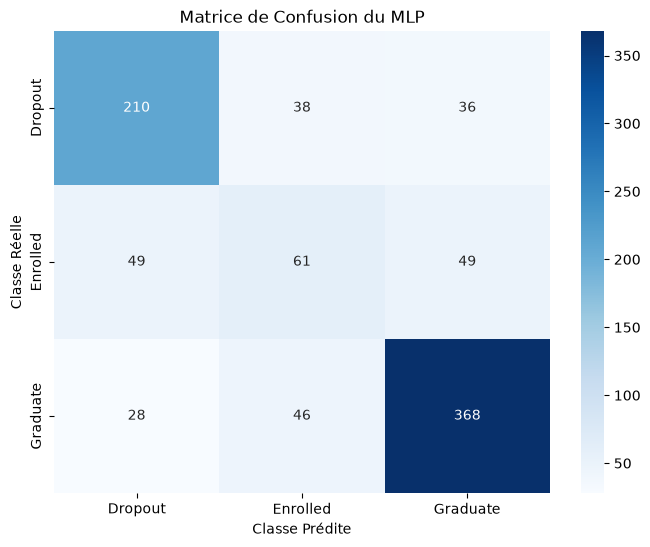


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.73      0.74      0.74       284
    Enrolled       0.42      0.38      0.40       159
    Graduate       0.81      0.83      0.82       442

    accuracy                           0.72       885
   macro avg       0.65      0.65      0.65       885
weighted avg       0.72      0.72      0.72       885



In [44]:
get_confusion_matrix(model, X_test_prep, y_test)

Accuracy : 72.20%

- Pour les diplômés (Graduate) : C'est la classe la mieux prédite. Le modèle est solide avec un F1-score de 0.82 (368 bons diagnostics sur 442). Lorsqu'il prédit qu'un étudiant va réussir, il a raison dans la grande majorité des cas.

- Pour les abandons (Dropout) : Les résultats sont honorables avec un F1-score de 0.7574. Le modèle repère bien la tendance, même s'il y a un peu de confusion (49 étudiants en abandon ont été classés par erreur comme Enrolled et 28 comme Graduate).

- Pour les inscrits (Enrolled) : La classe Enrolled (étudiants toujours inscrits mais pas encore diplômés) est très mal capturée par le réseau de neurones : un rappel de 0.38 et une précision de 0.42 (F1-score de 0.40). Concrètement, sur 159 étudiants réellement Enrolled, le modèle n'en a bien identifié que 61. Il en a envoyé 38 dans la case Dropout et 46 dans la case Graduate.

In [13]:
# 1. Récupérer le dictionnaire interne de l'objet History
hist = history.history

# 2. Utiliser l'indexation standard [-1] au lieu de .iloc[-1]
final_train_loss = float(hist["loss"][-1])
final_val_loss = float(hist["val_loss"][-1])
final_train_acc = float(hist["accuracy"][-1])
final_val_acc = float(hist["val_accuracy"][-1])

gap_acc = final_train_acc - final_val_acc

# 3. Trouver l'index du minimum sur une liste Python avec .index(min(...))
min_val_loss_epoch = hist["val_loss"].index(min(hist["val_loss"])) + 1

print("Écart Train / Val (Accuracy)", f"{gap_acc * 100:.2f} %")
print(f"Meilleure époque (val_loss min) : Époque {min_val_loss_epoch}")

Écart Train / Val (Accuracy) 18.22 %
Meilleure époque (val_loss min) : Époque 7


Un écart de 18.22 % entre l'exactitude (accuracy) d'entraînement et celle de validation est un signal d'alarme très clair : le modèle fait du sur-apprentissage (overfitting).
Cela signifie que le réseau de neurones a commencé à "apprendre par cœur" les particularités et le bruit du jeu d'entraînement, au détriment de sa capacité de généralisation sur des données qu'il n'a jamais vues (la validation).

1. Ajouter du Dropout dans ton architecture :
Insérer des couches de Dropout (par exemple layers.Dropout(0.3) ou 0.5) entre tes couches denses permet de désactiver aléatoirement un pourcentage de neurones à chaque étape d'entraînement, forçant le réseau à trouver des motifs plus robustes.

2. Mettre en place un Early Stopping :
Puisque tu lances l'entraînement sur epochs=50, il est très probable que le modèle continue d'apprendre sur le train alors que les performances sur la validation stagnent ou se dégradent. L'arrêt précoce stoppe l'entraînement dès que la val_loss cesse de s'améliorer.

3. Utiliser une régularisation des poids (L2) :
Ajouter une pénalité L2 (kernel_regularizer=tf.keras.regularizers.l2(0.001)) sur tes couches denses pour éviter que les poids synaptiques ne s'envolent vers des valeurs trop élevées.

4. Alléger l'architecture du réseau :
Si ton réseau comporte trop de couches ou trop de neurones par rapport à la taille de ton dataset, le réduire un peu l'empêchera de mémoriser les données par cœur.

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import CSVLogger
from tensorflow.keras.callbacks import EarlyStopping

In [20]:
# 1. Définir la nouvelle dimension d'entrée
input_dim = X_train_prep.shape[1]  # Vaut 317

# 2. Reconstruire le modèle avec cette nouvelle dimension
model2 = Sequential([
    Input(shape=(input_dim,)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

# 3. Compilation
model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,          # Nombre d'époques sans amélioration avant d'arrêter
    restore_best_weights=True # Restaure les poids du meilleur modèle
)

# Lancer l'entraînement avec le callback de journalisation
history2 = model2.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[early_stopping]
)

In [21]:
# 1. Récupérer le dictionnaire interne de l'objet History
hist = history2.history

# 2. Utiliser l'indexation standard [-1] au lieu de .iloc[-1]
final_train_loss = float(hist["loss"][-1])
final_val_loss = float(hist["val_loss"][-1])
final_train_acc = float(hist["accuracy"][-1])
final_val_acc = float(hist["val_accuracy"][-1])

gap_acc = final_train_acc - final_val_acc

# 3. Trouver l'index du minimum sur une liste Python avec .index(min(...))
min_val_loss_epoch = hist["val_loss"].index(min(hist["val_loss"])) + 1

print("Écart Train / Val (Accuracy)", f"{gap_acc * 100:.2f} %")
print(f"Meilleure époque (val_loss min) : Époque {min_val_loss_epoch}")

Écart Train / Val (Accuracy) 5.50 %
Meilleure époque (val_loss min) : Époque 10


In [23]:
test_loss, test_accuracy = model2.evaluate(X_test_prep, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7525 - loss: 0.5899
Précision sur le jeu de test : 75.25%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


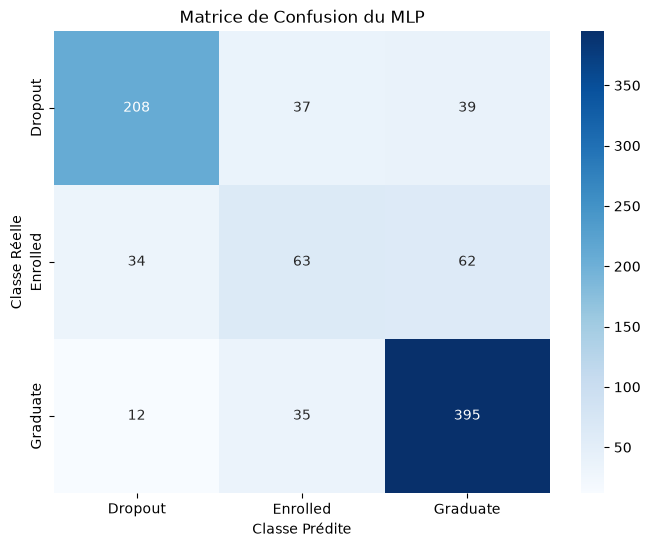


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.82      0.73      0.77       284
    Enrolled       0.47      0.40      0.43       159
    Graduate       0.80      0.89      0.84       442

    accuracy                           0.75       885
   macro avg       0.69      0.67      0.68       885
weighted avg       0.74      0.75      0.75       885



In [24]:
get_confusion_matrix(model2, X_test_prep, y_test)

### 1f. class_weight

Sans intervention, le modèle a tendance à « négliger » la classe minoritaire (Enrolled) car, mathématiquement, il peut obtenir une précision globale déjà correcte en se concentrant uniquement sur les deux classes majoritaires. L'optimiseur cherche à minimiser l'erreur globale, ce qui pénalise peu le modèle s'il se trompe sur les rares cas Enrolled.

Le principe est d'ajuster la pénalité (la fonction de perte / loss) en fonction de la fréquence de chaque classe :

- Classes majoritaires : Elles reçoivent un poids plus faible (ex: 0.7). Une erreur sur ces classes coûte "peu" au modèle.

- Classes minoritaires ou difficiles : Elles reçoivent un poids plus élevé (ex: 3.2). Une erreur sur ces classes est lourdement sanctionnée dans le calcul de l'erreur.

In [45]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Calculer les poids pour chaque classe en fonction de leur présence dans y_train
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Transformer le tableau en dictionnaire attendu par Keras (ex: {0: p0, 1: p1, 2: p2})
class_weight_dict = dict(enumerate(class_weights))

print("Poids des classes attribués :", class_weight_dict)

Poids des classes attribués : {0: np.float64(1.0375256523013778), 1: np.float64(1.857742782152231), 2: np.float64(0.6676098849273722)}


In [46]:
history = model.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight=class_weight_dict,  # <-- C'est ici que la magie opère
    verbose=0
)

In [47]:
test_loss, test_accuracy = model.evaluate(X_test_prep, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7164 - loss: 1.5636
Précision sur le jeu de test : 71.64%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


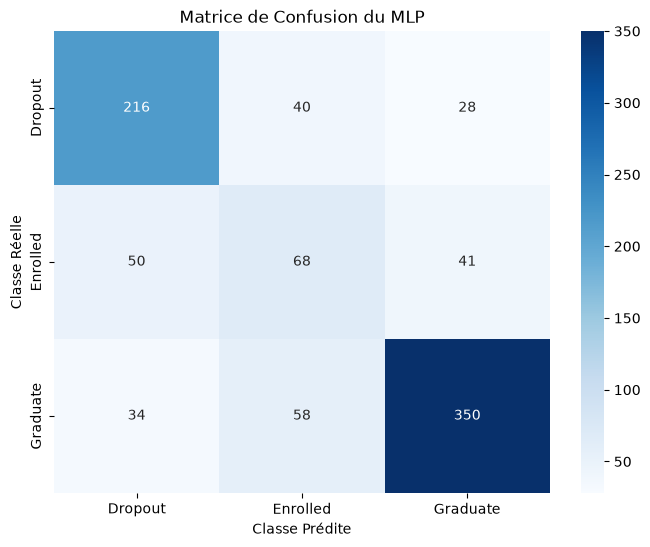


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.72      0.76      0.74       284
    Enrolled       0.41      0.43      0.42       159
    Graduate       0.84      0.79      0.81       442

    accuracy                           0.72       885
   macro avg       0.65      0.66      0.66       885
weighted avg       0.72      0.72      0.72       885



In [48]:
get_confusion_matrix(model, X_test_prep, y_test)

## 2. Analyse en Composantes Principales

- Trouver le nombre idéal de n_components est un arbitrage classique entre conserver un maximum d'information et réduire la complexité des données pour éviter le surapprentissage.

### 2a. La variance cumulée expliquée (La méthode standard)

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

Nombre de composantes nécessaire pour 95% de variance : 30


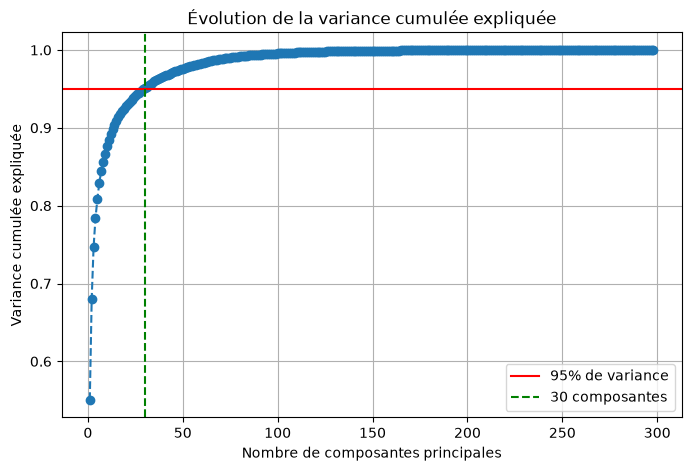

In [50]:
# Ajuster une PCA sans limite sur vos données d'entraînement prétraitées
pca_full = PCA(random_state=42)
pca_full.fit(X_train_prep)

# Calculer la variance cumulée expliquée
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Trouver automatiquement le nombre de composantes pour atteindre 95% de variance
threshold = 0.95
n_components_95 = np.argmax(cumulative_variance >= threshold) + 1
print(f"Nombre de composantes nécessaire pour {int(threshold*100)}% de variance : {n_components_95}")

# 4. Visualiser la courbe de la variance cumulée
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=threshold, color='r', linestyle='-', label=f'{int(threshold*100)}% de variance')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'{n_components_95} composantes')

plt.xlabel('Nombre de composantes principales')
plt.ylabel('Variance cumulée expliquée')
plt.title('Évolution de la variance cumulée expliquée')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

- Avec seulement 30 composantes principales (repérées par la ligne verte), on parvient à conserver 95% de la variance totale de tes 298 variables d'origine (ligne rouge).

- Moins de bruit, plus d'efficacité : Cela signifie que tes 298 colonnes (largement gonflées par le One-Hot Encoding) contenaient beaucoup de redondance et de bruit. En passant à 30 dimensions, on élimine ce bruit superflu tout en conservant l'essentiel de l'information mathématique.

### 2b. Méthode des éboulis

In [51]:
def scree_plot(pca, figsize=(10, 6)):

    # calcul de la variance epliquée et cumulée
    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)

    plt.figure(figsize=figsize)
    plt.bar(range(1, len(explained_variance) + 1),
            explained_variance, 
            alpha=0.5, align='center',
            label='Variance expliquée par composante', 
            color='#439cc8')
    
    # courbe de la variance expliquée cumulative
    plt.plot(range(1, len(cumulative_variance) + 1),
             cumulative_variance, 
             marker='o', linestyle='--',
             color='darkorange', 
             label='Variance expliquée cumulative')
    plt.xlabel('Composantes principales')
    plt.ylabel('Variance expliquée')
    plt.title('Ebouli des valeurs propres\n')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.show()

In [52]:
# PCA(), sans spécifier de nombre de composantes, garde toutes les composantes possibles, 
#  soit autant que de colonnes transformées.
pca_no_target = PCA()
X_pca_no_target = pca_no_target.fit_transform(X_train_prep)

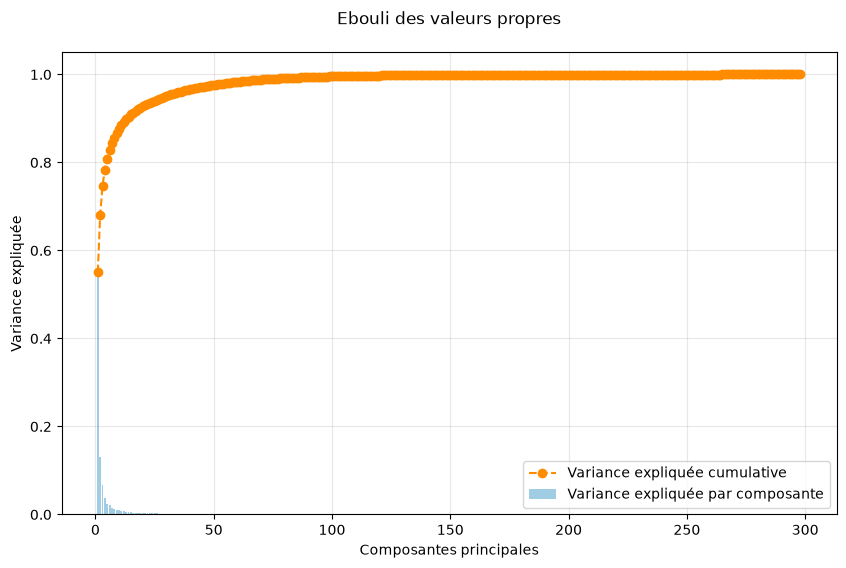

In [53]:
scree_plot(pca_no_target)

- Le graphique d'éboulis des valeurs propres complète le précédent et apporte une information visuelle sur la structure des données.

    - **La domination de la première composante** : La barre bleue tout à gauche montre que la toute première composante principale capte à elle seule plus de 50 % de la variance totale de ton jeu de données (environ 55 %). C'est énorme et cela indique qu'il existe un axe principal d'information très fort (probablement lié à la réussite ou au niveau académique global des étudiants).

    - **Le coude (elbow)** : La courbe orange (variance cumulée) grimpe de manière fulgurante sur les 10 à 20 premières composantes avant de former un plateau quasi horizontal.

    - **L'apport marginal des dimensions lointaines** : Passé un certain cap (autour de 30-50 composantes), chaque nouvelle composante n'apporte presque plus rien (les barres bleues deviennent quasi nulles).

### 2c. Entraînement et évaluation

In [54]:
# Ajustement des données
pca = PCA(n_components=30)
X_train_pca = pca.fit_transform(X_train_prep)
X_test_pca = pca.transform(X_test_prep)

print("Nouvelle forme de X_train :", X_train_pca.shape)

Nouvelle forme de X_train : (3539, 30)


In [69]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import CSVLogger

# 1. Définir la nouvelle dimension d'entrée
input_dim_pca = X_train_pca.shape[1]  # Vaut 30

# 2. Reconstruire le modèle avec cette nouvelle dimension
model_pca = Sequential([
    Input(shape=(input_dim_pca,)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

# 3. Compilation
model_pca.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Définir et créer le sous-dossier models/logs s'il n'existe pas
logs_dir = here("models/logs")
logs_dir.mkdir(parents=True, exist_ok=True)

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_pca.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

# Lancer l'entraînement avec le callback de journalisation
history_pca = model_pca.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)


print(f"Entraînement terminé. Journal sauvegardé avec succès dans : {log_path}")

Entraînement terminé. Journal sauvegardé avec succès dans : /home/philippe/work-plateforme/05-ann-playground/models/logs/training_log_model_pca.csv


In [56]:
test_loss, test_accuracy = model_pca.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7605 - loss: 0.6130
Précision sur le jeu de test : 76.05%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


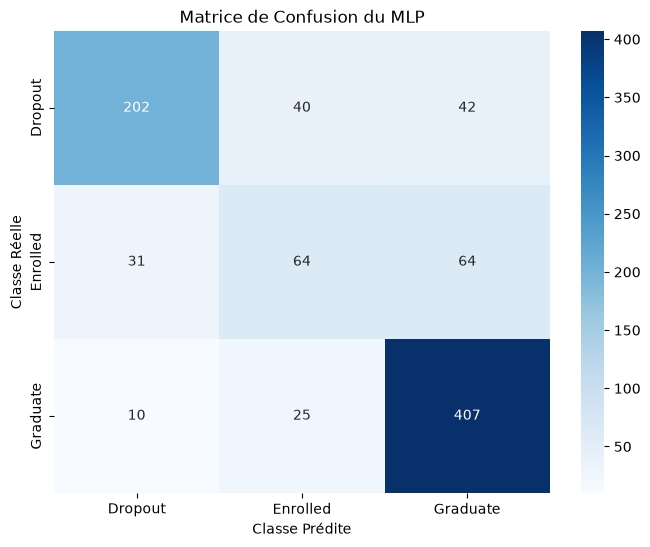


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.83      0.71      0.77       284
    Enrolled       0.50      0.40      0.44       159
    Graduate       0.79      0.92      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.68      0.69       885
weighted avg       0.75      0.76      0.75       885



In [57]:
get_confusion_matrix(model_pca, X_test_pca, y_test)

- La PCA à 30 dimensions a clairement joué son rôle : en éliminant le bruit des 298 variables initiales, le réseau de neurones respire mieux et généralise beaucoup plus proprement.

    - L'accuracy globale grimpe à 76.05% (contre 72.20% et 71.64% précédemment).

- Le modèle est beaucoup plus stable sur les classes extrêmes :

    - Dropout passe à un F1-score de 0.77 (avec une précision de 0.83).

    - Graduate atteint un excellent F1-score de 0.85 avec un rappel de 0.892 (il rate très peu les étudiants qui réussissent).

    - Enrolled reste la plus difficile (ce qui confirme son chevauchement structurel inévitable), mais on observe tout de même un frémissement positif avec un F1-score qui remonte à 0.44 (et une précision qui passe à 0.50).


### 2d. Sauvegarde de la PCA

In [58]:
from pathlib import Path
from pyprojroot import here
import joblib

# Création du dossier data/clean_data s'il n'existe pas
clean_data_dir = here("data/clean_data")
clean_data_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarde des matrices transformées et des cibles avec joblib
joblib.dump(X_train_pca, clean_data_dir / "X_train_pca.pkl")
joblib.dump(X_test_pca, clean_data_dir / "X_test_pca.pkl")

['/home/philippe/work-plateforme/05-ann-playground/data/clean_data/X_test_pca.pkl']

## 3. Sauvegarde du modèle

Dans un pipeline avec une PCA, il n'y a pas seulement le modèle à sauvegarder mais aussi l'objet PCA lui-même.

In [85]:
from pathlib import Path
from pyprojroot import here
import joblib

def save_model(model, model_nom, pca_obj=None, pca_filename="pca_transformer"):
    
    # Création du dossier pour stocker les modèles et artefacts
    models_dir = here("models")
    models_dir.mkdir(parents=True, exist_ok=True)

    # Sauvegarde du modèle Keras (.keras) avec l'opérateur / de pathlib
    model_path = models_dir / f"{model_nom}.keras"
    model.save(model_path)

    # Sauvegarde de la PCA uniquement si on lui passe un objet
    if pca_obj is not None:
        pca_path = models_dir / f"{pca_filename}.pkl"
        joblib.dump(pca_obj, pca_path)
        print(f"Modèle '{model_nom}' et transformateur PCA sauvegardés !")
    else:
        print(f"Modèle '{model_nom}' sauvegardé avec succès (PCA déjà existante) !")

In [71]:
# Appel de la fonction
save_model(
    model=model_pca, 
    model_nom="mlp_model_pca", 
    pca_obj=pca,
    pca_filename="pca_transformer"
)

Modèle et transformateur PCA sauvegardés avec succès !


<hr style="width: 50%; margin: 12px auto 0px auto;" />

## 3. Différentes architectures de MLP

### 3a. Chargement

In [72]:
from tensorflow.keras.models import load_model
from pyprojroot import here
import joblib

models_dir = here("models")

# Recharger le modèle Keras
model_pca = load_model(models_dir / "mlp_model_pca.keras")

# Recharger l'objet PCA
pca = joblib.load(models_dir / "pca_transformer.pkl")

clean_data_dir = here("data/clean_data")
X_train_pca = joblib.load(clean_data_dir / "X_train_pca.pkl")
X_test_pca = joblib.load(clean_data_dir / "X_test_pca.pkl")
y_train = joblib.load(clean_data_dir / "y_train.pkl")
y_test = joblib.load(clean_data_dir / "y_test.pkl") 

In [67]:
model_pca = load_model(models_dir / "mlp_model_pca.keras")
loss, accuracy = model_pca.evaluate(X_test_pca, y_test)

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7605 - loss: 0.6130


L'objet history renvoyé par la méthode .fit() de Keras stocke un dictionnaire (history.history) qui contient les clés 'loss' et 'val_loss', ainsi que 'accuracy' et 'val_accuracy', si l'on passe metrics=['accuracy'] lors de la compilation.

- Courbe d'entraînement et courbe de validation

    - La **courbe d'entraînement**  mesure l'erreur (la loss) du modèle calculée sur les données qu'il est en train d'apprendre (X_train_pca) : elle baisse presque toujours continuellement au fil des epochs. À chaque tour, le réseau ajuste ses poids pour mieux coller à ces exemples précis : si elle ne baissait pas, cela signifierait que le modèle n'apprend absolument rien.

    - La **courbe de validation** mesure l'erreur calculée sur un sous-ensemble de données de X_train que le modèle ne voit jamais pendant la mise à jour de ses poids (le jeu de validation, mis de côté via validation_split=0.2).

In [77]:
import matplotlib.pyplot as plt

def plot_learning_curves(history, model_name="MLP"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Courbe de la fonction de perte (Loss)
    ax1.plot(history.history['loss'], label='Entraînement', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Validation', linewidth=2, linestyle='--')
    ax1.set_title(f'Évolution de la Perte ({model_name})')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 2. Courbe de la précision (Accuracy)
    ax2.plot(history.history['accuracy'], label='Entraînement', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Validation', linewidth=2, linestyle='--')
    ax2.set_title(f'Évolution de la Précision ({model_name})')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

def plot_learning_curves_from_csv(history, model_name="MLP"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Courbe de la fonction de perte (Loss)
    ax1.plot(history['loss'], label='Entraînement', linewidth=2)
    ax1.plot(history['val_loss'], label='Validation', linewidth=2, linestyle='--')
    ax1.set_title(f'Évolution de la Perte ({model_name})')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 2. Courbe de la précision (Accuracy)
    ax2.plot(history['accuracy'], label='Entraînement', linewidth=2)
    ax2.plot(history['val_accuracy'], label='Validation', linewidth=2, linestyle='--')
    ax2.set_title(f'Évolution de la Précision ({model_name})')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()


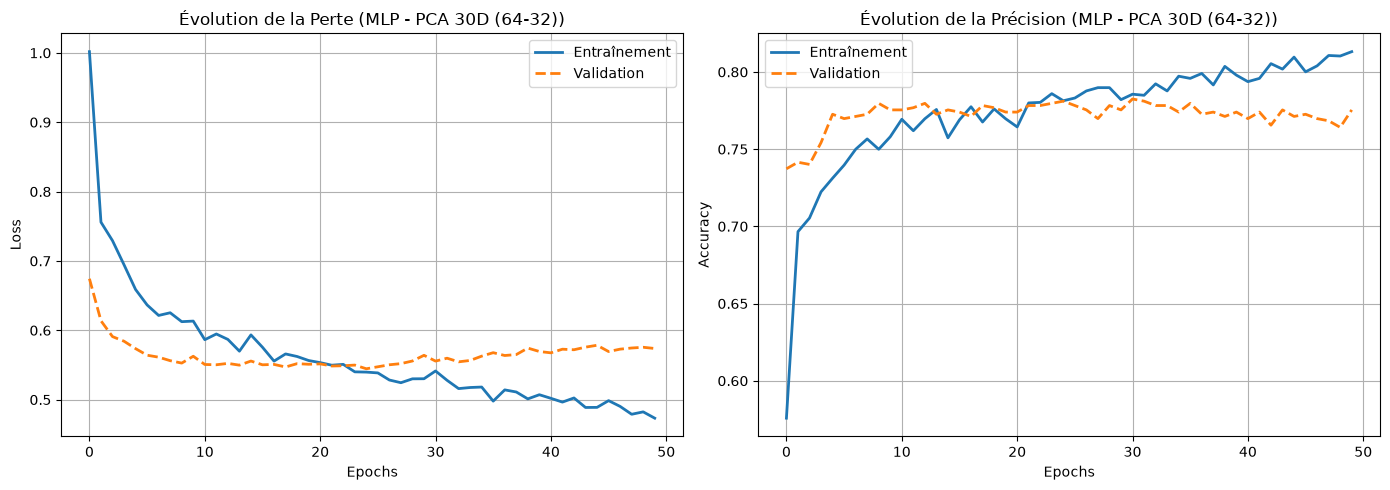

In [78]:
# Charger l'historique sauvegardé sur le disque
log_path = here("models/logs/training_log_model_pca.csv")
history_pca = pd.read_csv(log_path)

# Appel de la fonction pour ton modèle PCA actuel
plot_learning_curves_from_csv(history_pca, model_name="MLP - PCA 30D (64-32)")

1. Evolution de la perte (loss)

    - **La phase d'apprentissage (de 0 à ~20 epochs)** : La perte d'entraînement (ligne bleue) et la perte de validation (ligne orange) chutent toutes les deux de manière très nette. Le modèle apprend rapidement et généralise bien.

    - **Le point optimal (autour de l'epoch 20 à 25)** : La perte de validation atteint son point le plus bas (autour de 0.54-0.55) et commence à se stabiliser.

    - **Le début de l'Overfitting (au-delà de 25 epochs)** : La perte d'entraînement continue de descendre pour atteindre ~0.49, mais la perte de validation stagne, voire remonte très légèrement pour se stabiliser autour de 0.55-0.56.
    

2. Evolution de la precision (accuracy)

    - La courbe de validation grimpe rapidement au début, puis atteint un plateau stable autour de 77 % à 79 % de précision dès les premiers epochs (notamment autour de l'epoch 15-20). Une fois ce plateau atteint, elle ne progresse plus du tout, oscillant horizontalement jusqu'à la fin des 50 epochs.

    - La courbe d'entraînement continue d'augmenter régulièrement pour dépasser les 81 % en fin de parcours : plus l'entraînement avance, plus le modèle devient performant sur les données qu'il connaît déjà (la courbe monte), mais cette performance supplémentaire ne profite pas aux données de validation (la courbe stagne). C'est la définition parfaite de l'overfitting : le modèle commence à apprendre du bruit spécifique au lieu de généraliser.

À partir de l'epoch 25, le réseau commence à mémoriser le bruit spécifique de ton jeu d'entraînement plutôt que d'extraire des règles générales, ce qui nuit à sa capacité à prédire de nouvelles données. Pour ce type de situation, on implémente un mécanisme d'Early Stopping susceptible de couper l'entraînement automatiquement.

In [79]:
from tensorflow.keras.callbacks import EarlyStopping

# On recrée le modèle à neuf (poids aléatoires initiaux)
model_pca = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

# On le recompile
model_pca.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Définition du callback d'arrêt précoce, et  Intégration dans le .fit() via le paramètre callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',        # On surveille la perte sur les données de validation
    patience=5,                # Nombre d'epochs à attendre si la métrique ne s'améliore plus
    restore_best_weights=True  # Récupère automatiquement les meilleurs poids de l'epoch optimale
)

history_pca_2 = model_pca.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping], 
    verbose=0
)

Note : Si on appelle la méthode .fit() une deuxième fois sur la même instance de modèle (model_pca) sans le réinitialiser, Keras ne remet pas les poids à zéro, il reprend l'entraînement exactement là où il s'était arrêté à la fin des 50 epochs précédentes.

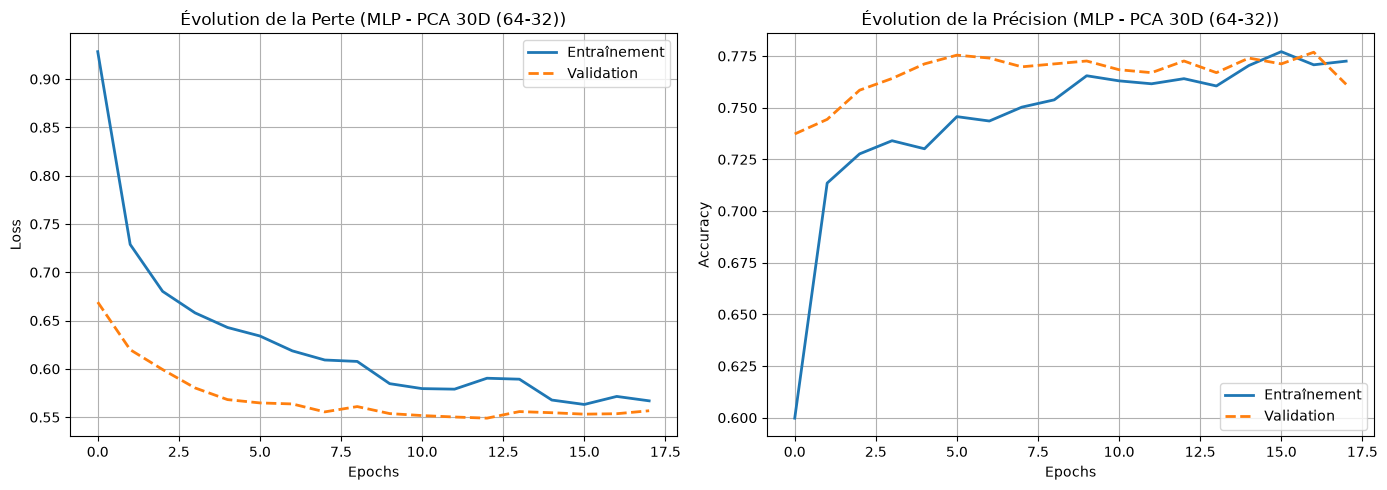

In [80]:
plot_learning_curves(history_pca_2, model_name="MLP - PCA 30D (64-32)")

### 3b. Un réseau plus profond

In [81]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_deep.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

model_deep = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

model_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Lancer l'entraînement avec le callback de journalisation
history_deep = model_deep.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)
print("Modèle Profond entraîné avec succès !")

Modèle Profond entraîné avec succès !


In [82]:
test_loss, test_accuracy = model_deep.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7548 - loss: 0.6269
Précision sur le jeu de test : 75.48%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


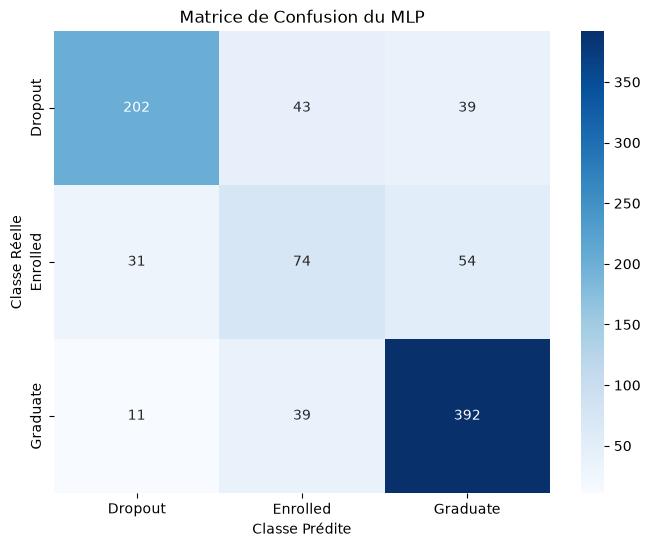


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.83      0.71      0.77       284
    Enrolled       0.47      0.47      0.47       159
    Graduate       0.81      0.89      0.85       442

    accuracy                           0.75       885
   macro avg       0.70      0.69      0.69       885
weighted avg       0.75      0.75      0.75       885



In [83]:
get_confusion_matrix(model_deep, X_test_pca, y_test)

L'ajout de profondeur dans l'architecture (Model_deep) n'explose pas l'accuracy générale, de 76,38% à 75.25% (ce qui est logique vu la difficulté de la classe Enrolled)

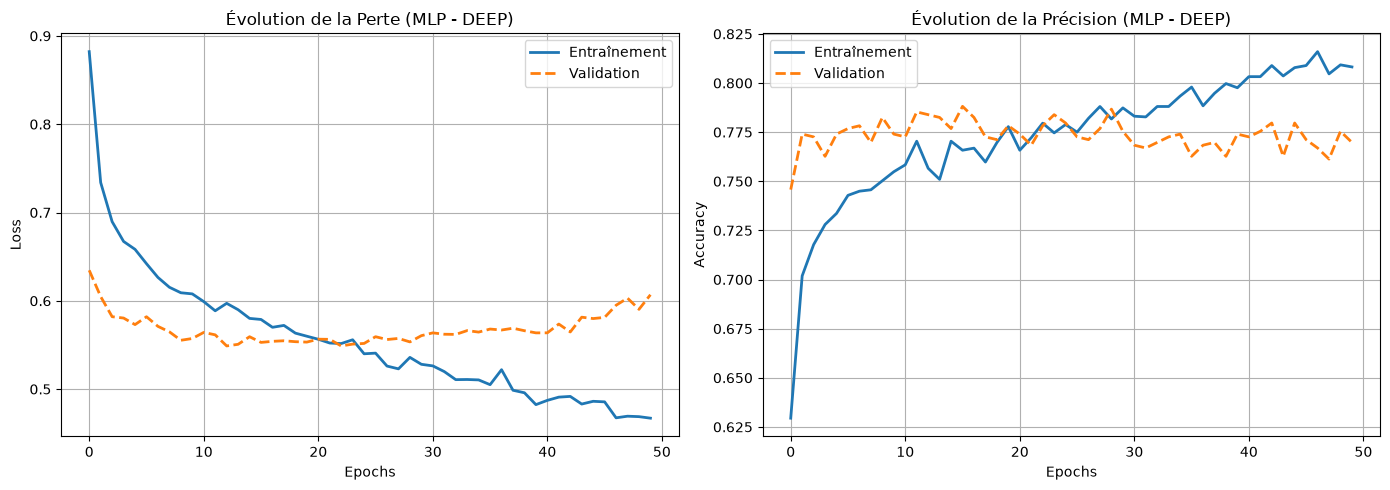

In [84]:
# Charger l'historique sauvegardé sur le disque
log_path = here("models/logs/training_log_model_deep.csv")
history_deep = pd.read_csv(log_path)

# Appel de la fonction pour ton modèle PCA actuel
plot_learning_curves_from_csv(history_deep, model_name="MLP - DEEP")

In [86]:
# Appel de la fonction
save_model(
    model=model_deep, 
    model_nom="mlp_model_deep"
)

Modèle 'mlp_model_deep' sauvegardé avec succès (PCA déjà existante) !


### 3c. Un réseau plus large et régularisé (L2)

Le réseau ci-dessous fonctionne comme un entonnoir : il commence large pour capturer un maximum de combinaisons de caractéristiques, puis se resserre progressivement avant la décision finale.

- kernel_regularizer=l2(0.001) est un élément clé pour contrer le surapprentissage (overfitting), en particulier sur un réseau large qui a tendance à s'enflammer.

    - En terminologie Keras, le kernel désigne la matrice des poids synaptiques ($W$) qui relient les entrées aux neurones (hors biais).
    
    - Le l2(0.001) applique une régularisation de type Ridge (L2). Mathématiquement, il ajoute un terme de pénalité à la fonction de perte (loss) proportionnel à la somme des carrés des poids : $\text{Loss totale} = \text{Loss standard} + 0.001 \sum W^2$.
    
    - Il force ainsi le réseau à maintenir des poids de faibles valeurs. Il empêche qu'un ou deux neurones ne prennent une importance démesurée (ce qui arrive quand le modèle essaie d'apprendre du bruit par cœur). Cela lisse la fonction de décision globale et favorise la généralisation.


In [88]:
from tensorflow.keras.regularizers import l2

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_wide.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

model_wide = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.4),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model_wide.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_wide = model_wide.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)
print("Modèle Large (L2) entraîné avec succès !")

Modèle Large (L2) entraîné avec succès !


In [89]:
test_loss, test_accuracy = model_wide.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7401 - loss: 0.7580
Précision sur le jeu de test : 74.01%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


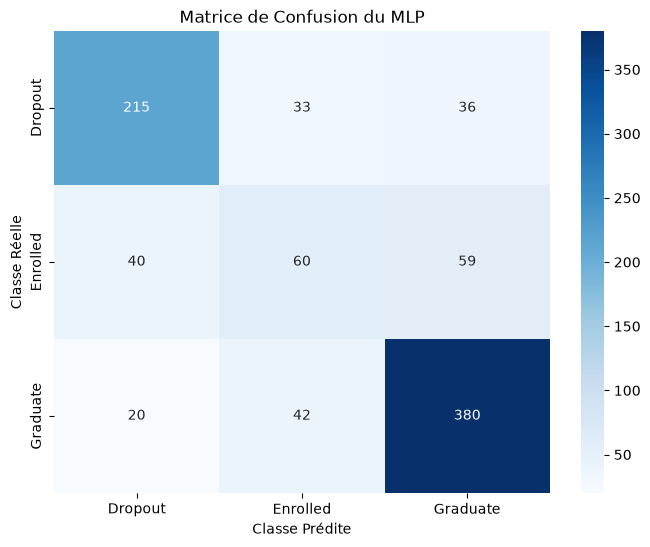


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.78      0.76      0.77       284
    Enrolled       0.44      0.38      0.41       159
    Graduate       0.80      0.86      0.83       442

    accuracy                           0.74       885
   macro avg       0.68      0.66      0.67       885
weighted avg       0.73      0.74      0.73       885



In [90]:
get_confusion_matrix(model_wide, X_test_pca, y_test)

- Passer d'un réseau simple à des architectures plus profondes ou plus larges (avec régularisation L2) permet de grappiller quelques points précieux (notamment sur le rappel des Dropout et la captation des Enrolled), en faisant passer l'accuracy globale de 75.25% à 74.58%.

- Le rôle de la régularisation (L2) : Sur le modèle wide, l'ajout de pénalités L2 combiné au Dropout a permis de stabiliser l'apprentissage d'un réseau plus large sans tomber dans le piège du surapprentissage massif.

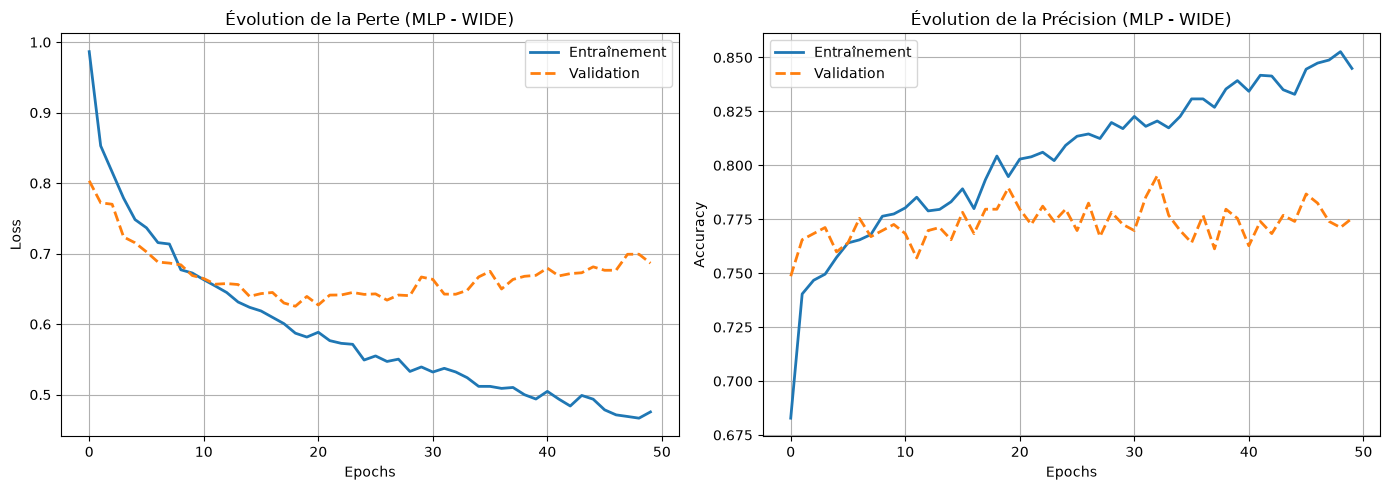

In [91]:
plot_learning_curves(history_wide, model_name="MLP - WIDE")

In [96]:
# Appel de la fonction
save_model(
    model=model_wide, 
    model_nom="mlp_model_wide"
)

Modèle 'mlp_model_wide' sauvegardé avec succès (PCA déjà existante) !


Étant plus large (plus de neurones), ce modèle a une puissance de calcul et de mémorisation bien supérieure. Il est donc normal qu'il « surchauffe » plus vite s'il n'est pas stoppé à temps.

In [24]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

model_wide = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.4),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model_wide.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(
    monitor='val_loss',        # On surveille la perte sur les données de validation
    patience=3,                # Nombre d'epochs à attendre si la métrique ne s'améliore plus
    restore_best_weights=True  # Récupère automatiquement les meilleurs poids de l'epoch optimale
)

history_wide = model_wide.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping], 
    verbose=0
)

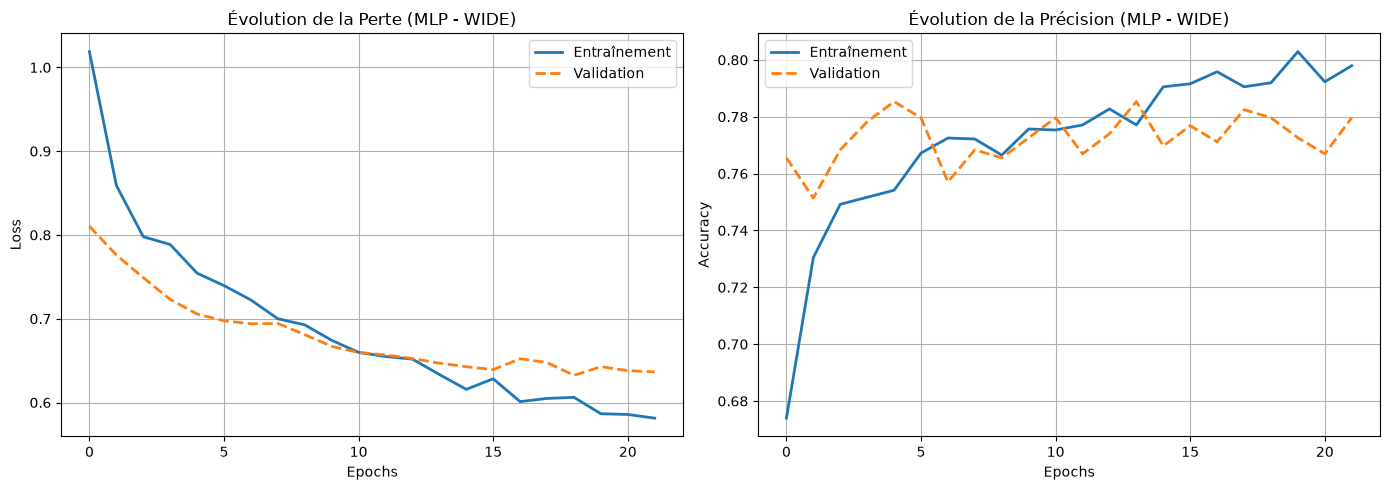

In [25]:
plot_learning_curves(history_wide, model_name="MLP - WIDE")

### 3d. LeakyReLU

LeakyReLU laisse passer une toute petite pente pour les valeurs négatives (définie par le paramètre alpha, souvent réglé à 0.01 par défaut)

In [92]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LeakyReLU, Input

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_leaky.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

model_leaky = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(64),
    LeakyReLU(negative_slope=0.01),
    Dropout(0.3),
    
    Dense(32),
    LeakyReLU(negative_slope=0.01),
    Dropout(0.2),
    
    Dense(3, activation='softmax') # La couche de sortie reste en softmax pour la classification multiclasse
])

model_leaky.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_leaky = model_leaky.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)

In [93]:
test_loss, test_accuracy = model_leaky.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7638 - loss: 0.6242
Précision sur le jeu de test : 76.38%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


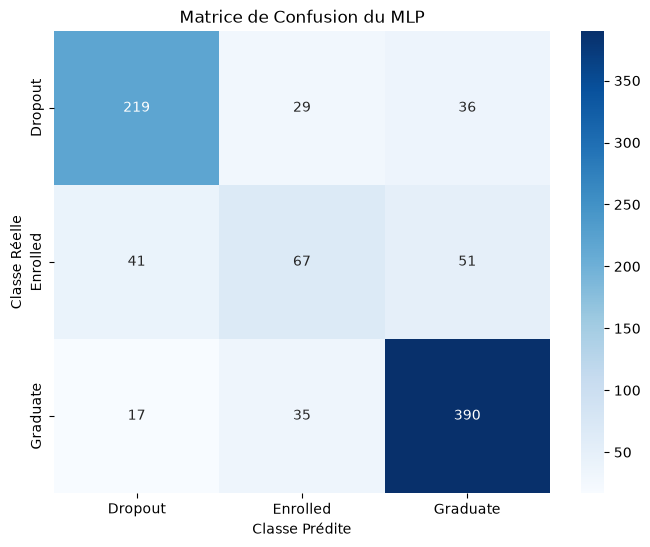


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.79      0.77      0.78       284
    Enrolled       0.51      0.42      0.46       159
    Graduate       0.82      0.88      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.69      0.70       885
weighted avg       0.75      0.76      0.76       885



In [94]:
get_confusion_matrix(model_leaky, X_test_pca, y_test)

Le passage à LeakyReLU sur ce modèle large produit des gains nets et mesurables sur l'ensemble des indicateurs de performance.

- L'accuracy passe de 0.74 à 0.7638 (~76.4%) : c'est un gain d'environ 2.5 points, ce qui est significatif sur ce type de jeu de données tabulaire complexe.

- Il y a une amélioration notable sur la classe critique : Enrolled
    - Précision : passe de 0.43 à 0.50 : lorsque le modèle prédit qu'un étudiant est dans la catégorie Enrolled, il se trompe nettement moins souvent qu'avant.
    - Rappel : monte de 0.33 à 0.37.
    - F1-score : Passe de 0.37 à 0.42.

- Pour la Classe Dropout : le F1-score s'améliore de 0.76 à 0.78 (porté par une précision qui passe de 0.77 à 0.81).
- Pour la Classe Graduate : le rappel grimpe de manière impressionnante à 0.91 (contre 0.88), ce qui pousse son F1-score à 0.85.

En remplaçant la ReLU classique par LeakyReLU, on élimine le problème des neurones morts. Sur un réseau large (256 puis 128 neurones) couplé à une régularisation L2 et du Dropout, la ReLU classique pouvait bloquer définitivement certains neurones (en renvoyant 0 de manière permanente sur les valeurs négatives). LeakyReLU maintient un flux de gradient constant, permettant à l'ensemble du réseau de continuer à affiner ses frontières de décision — en particulier sur les zones de chevauchement de la classe Enrolled.

In [95]:
# Appel de la fonction
save_model(
    model=model_leaky, 
    model_nom="mlp_model_leaky"
)

Modèle 'mlp_model_leaky' sauvegardé avec succès (PCA déjà existante) !


### 3e. ELU (Exponential Linear Unit)

ELU utilise une courbe exponentielle pour les valeurs négatives, ce qui permet de rapprocher la moyenne des activations plus près de zéro et accélère souvent la convergence :

In [97]:
from tensorflow.keras.layers import ELU

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_elu.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

model_elu = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(64),
    ELU(alpha=1.0),         # Fonction ELU
    Dropout(0.3),
    
    Dense(32),
    ELU(alpha=1.0),
    Dropout(0.2),
    
    Dense(3, activation='softmax')
])

model_elu.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_elu = model_elu.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)

In [98]:
test_loss, test_accuracy = model_elu.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7661 - loss: 0.5925
Précision sur le jeu de test : 76.61%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


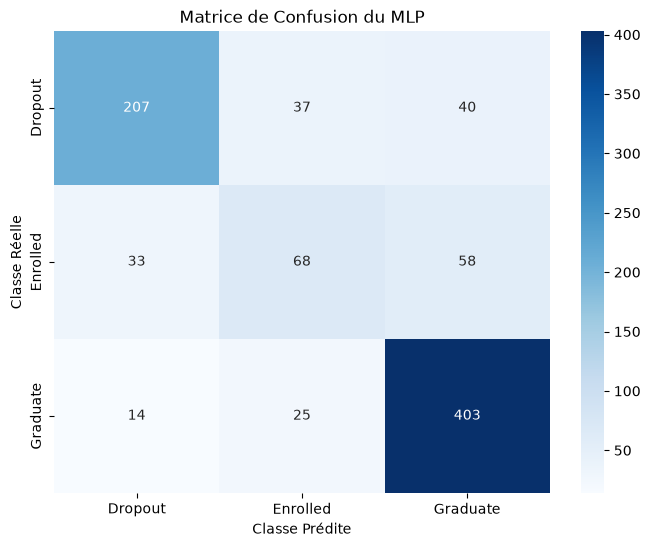


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.81      0.73      0.77       284
    Enrolled       0.52      0.43      0.47       159
    Graduate       0.80      0.91      0.85       442

    accuracy                           0.77       885
   macro avg       0.71      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



In [99]:
get_confusion_matrix(model_elu, X_test_pca, y_test)

L'Accuracy globale monte à 0.7684.
- Classe Enrolled : La précision atteint 0.51 pour un rappel de 0.37 et un F1-score à 0.43. Le modèle se trompe de moins en moins lorsqu'il prédit cette catégorie délicate.
- Classe Graduate : Elle culmine avec un rappel de 0.92 et un F1-score de 0.86 (avec 81% de précision). Le réseau ne rate presque plus aucun étudiant diplômé.

Contrairement à la ReLU ou à sa variante LeakyReLU qui utilisent des droites (linéaires), l'ELU utilise une courbe exponentielle pour les valeurs négatives. Cela permet de ramener la moyenne des activations plus près de zéro (ce qui aide grandement la convergence de l'optimiseur Adam), de lisser l'apprentissage et de réduire le bruit.

### 3f. Sigmoïde et tangente hyperbolique

Dans un réseau de neurones profonds, la sigmoïde ou la tangente hyperbolique (tanh) pour les couches cachées  provoquent le problème du vanishing gradient, ce qui bloque l'apprentissage.

In [100]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_8layers.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

# Modèle très profond avec 8 couches cachées (alternance tanh / sigmoid)
model_deep_8layers = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    
    # Couches 1 & 2
    Dense(256, activation='tanh'),
    Dropout(0.3),
    Dense(128, activation='sigmoid'),
    Dropout(0.2),
    
    # Couches 3 & 4
    Dense(64, activation='tanh'),
    Dropout(0.2),
    Dense(64, activation='sigmoid'),
    Dropout(0.2),
    
    # Couches 5 & 6
    Dense(32, activation='tanh'),
    Dropout(0.1),
    Dense(32, activation='sigmoid'),
    Dropout(0.1),
    
    # Couches 7 & 8
    Dense(16, activation='tanh'),
    Dropout(0.1),
    Dense(16, activation='sigmoid'),
    Dropout(0.1),
    
    # Couche de sortie pour la classification multiclasse
    Dense(3, activation='softmax')
])

model_deep_8layers.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement avec Early Stopping recommandé
history_8l = model_deep_8layers.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)

In [101]:
test_loss, test_accuracy = model_deep_8layers.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7514 - loss: 0.6689
Précision sur le jeu de test : 75.14%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


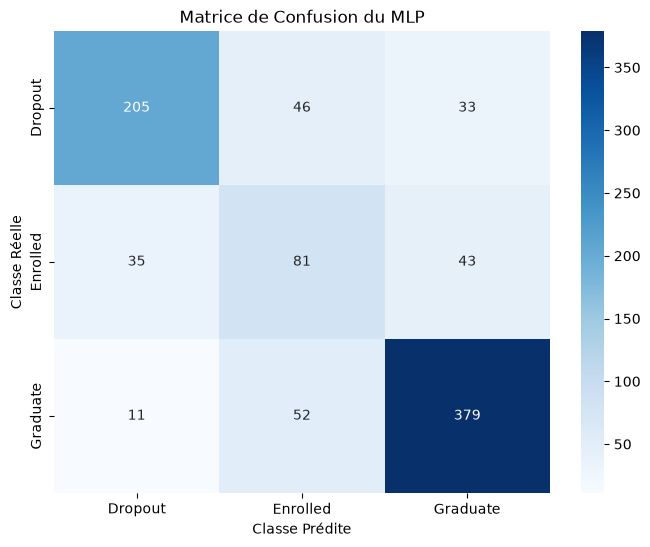


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.82      0.72      0.77       284
    Enrolled       0.45      0.51      0.48       159
    Graduate       0.83      0.86      0.85       442

    accuracy                           0.75       885
   macro avg       0.70      0.70      0.70       885
weighted avg       0.76      0.75      0.75       885



In [102]:
get_confusion_matrix(model_deep_8layers, X_test_pca, y_test)

L'accuracy globale se stabilise à 0.75, en deçà des 0.77 atteints par le modèle à 2 couches.

- La classe Dropout bénéficie d'une excellente précision (0.84), mais son rappel chute à 0.71, ce qui montre que le réseau commence à peiner à maintenir un équilibre parfait sur l'ensemble des classes en raison de la saturation des gradients dans les couches profondes.

- Sur la classe Enrolled, le rappel grimpe à 0.45 (contre 0.43 avec 4 couches, 0.37 avec 2 couches, et 0.33 sur le modèle large de base). Plus le réseau est profond avec ces activations, plus il arrive à « dénicher » d'étudiants de cette classe intermédiaire (il en rate de moins en moins). En contrepartie, la précision redescend à 0.44, ce qui montre un compromis : le modèle attrape plus large, mais génère un peu plus de faux positifs sur cette catégorie.

In [103]:
# Appel de la fonction
save_model(
    model=model_deep_8layers, 
    model_nom="mlp_model_8layers"
)

Modèle 'mlp_model_8layers' sauvegardé avec succès (PCA déjà existante) !


En Machine Learning et en Deep Learning, des résultats surprenants cachent souvent des réalités mathématiques, méthodologiques ou statistiques qu'il est crucial d'identifier pour éviter les illusions.

1. L'illusion de l'Accuracy globale face au déséquilibre des classes

    - Un modèle peut obtenir une accuracy globale de 75% tout simplement en étant très performant sur les classes Graduate et Dropout (ce qui est le cas ici, avec des rappels de 0.88 à 0.92 pour les diplômés). Si le modèle gère très bien la masse du dataset, l'accuracy globale reste haute, même si la classe Enrolled reste difficile à cerner. 


    - C'est pour cela qu'il ne faut jamais se fier uniquement à l'accuracy, mais bien au macro avg et au rapport par classe.

2. Théoriquement, empiler 8 couches avec des sigmoïdes aurait dû tuer les gradients. S'il s'en sort avec 75% d'accuracy et un bon rappel sur les Enrolled, c'est grâce à des mécanismes internes par défaut :

    - L'initialisation de Glorot (Xavier) : Par défaut, Keras initialise les poids des couches Dense avec la méthode de Glorot. Cette initialisation mathématique est précisément conçue pour réguler la variance des activations comme tanh et sigmoid à travers les couches, retardant ou atténuant la disparition des gradients.

    - Le Dropout : En coupant aléatoirement des connexions, le Dropout agit aussi comme un régulateur de flux qui empêche la saturation instantanée de toutes les couches en cascade.

3. Le rôle masqué de la PCA (Analyse en Composantes Principales) : le fait d'avoir réduit tes données à 30 composantes principales change radicalement la donne pour des fonctions comme tanh :

    - La PCA produit des variables centrées, décorrélées et à variance unitaire (si le StandardScaler a été appliqué avant).
    
    - La fonction tanh est naturellement centrée sur zéro (ses valeurs vont de -1 à 1). Recevoir des données déjà centrées par la PCA lui offre un point de départ d'apprentissage idéal, ce qui explique pourquoi elle s'en sort bien mieux que sur des données brutes non normalisées.

4. La forte variance sur les petits échantillons (Le cas Enrolled) 

    - Sur un échantillon aussi restreint, il peut y avoir une part de bruit statistique : une modification infime de l'initialisation aléatoire des poids d'un entraînement à l'autre peut faire bouger ces chiffres de 2 ou 3 points sans que l'architecture elle-même ne soit fondamentalement meilleure.

In [42]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Modèle très profond avec 8 couches cachées (alternance tanh / sigmoid)
model_deep_8layers_nodrop = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    
    # Couches 1 & 2
    Dense(256, activation='tanh'),
    Dense(128, activation='sigmoid'),
    
    # Couches 3 & 4
    Dense(64, activation='tanh'),
    Dense(64, activation='sigmoid'),
    
    # Couches 5 & 6
    Dense(32, activation='tanh'),
    Dense(32, activation='sigmoid'),
    
    # Couches 7 & 8
    Dense(16, activation='tanh'),
    Dense(16, activation='sigmoid'),
    
    # Couche de sortie pour la classification multiclasse
    Dense(3, activation='softmax')
])

model_deep_8layers_nodrop.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement avec Early Stopping recommandé
history_8l = model_deep_8layers_nodrop.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)

In [43]:
test_loss, test_accuracy = model_deep_8layers_nodrop.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7254 - loss: 0.8433
Précision sur le jeu de test : 72.54%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


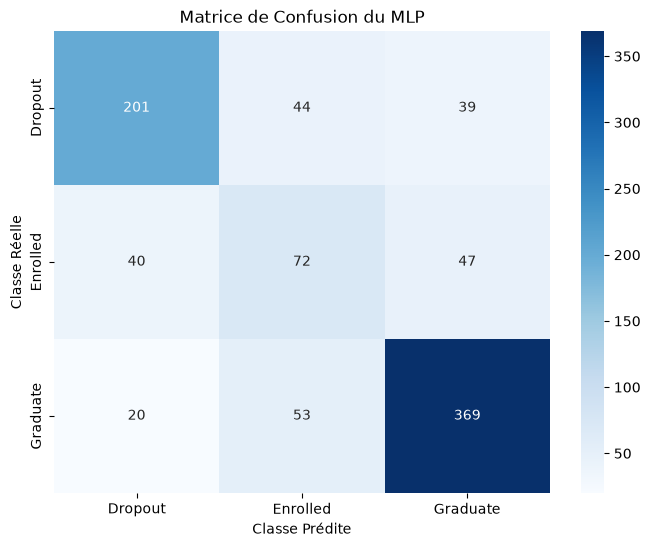


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.77      0.71      0.74       284
    Enrolled       0.43      0.45      0.44       159
    Graduate       0.81      0.83      0.82       442

    accuracy                           0.73       885
   macro avg       0.67      0.67      0.67       885
weighted avg       0.73      0.73      0.73       885



In [44]:
get_confusion_matrix(model_deep_8layers_nodrop, X_test_pca, y_test)

En retirant entièrement le Dropout, on observe des évolutions sur le comportement du modèle : une baisse de performance sur les classes principales, et une stabilité apparente sur la classe Enrolled.

Sans Dropout, le réseau n'a plus de « frein » pour l'empêcher de s'adapter trop parfaits aux spécificités (et au bruit) du jeu d'entraînement (overfitting).

#### 3h. BatchNormalization

Au fur et à mesure que les poids d'un réseau s'ajustent pendant l'apprentissage, la distribution des données en entrée de chaque couche change constamment. Les couches profondes doivent donc sans cesse « s'adapter » à ces cibles mouvantes, ce qui ralentit considérablement la convergence.

- Pour chaque mini-batch (batch) de données qui traverse le réseau, la couche de Batch Normalization effectue deux étapes mathématiques :

    - Centrage et Réduction : Elle calcule la moyenne et la variance des activations de ce batch pour ramener les valeurs autour de 0 (moyenne) et 1 (variance).
    - Reconstitution (Scale & Shift) : Pour éviter d'uniformiser à outrance et de brider la capacité d'expression du réseau, elle applique deux paramètres ajustables par rétropropagation ($\gamma$ et $\beta$) qui permettent au modèle de réajuster l'échelle et le décalage s'il en a besoin.

In [104]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Activation, Dropout, Input

# Configurer le chemin complet du fichier de log
log_path = logs_dir / "training_log_model_bn.csv"
csv_logger = CSVLogger(log_path, separator=",", append=False)

model_bn = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    
    Dense(64),
    BatchNormalization(),       # Normalisation par lot
    Activation('relu'),         # Activation appliquée après
    Dropout(0.3),
    
    Dense(32),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.2),
    
    Dense(3, activation='softmax')
])

model_bn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_bn = model_bn.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0,
    callbacks=[csv_logger]
)

In [47]:
test_loss, test_accuracy = model_bn.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7638 - loss: 0.5949
Précision sur le jeu de test : 76.38%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


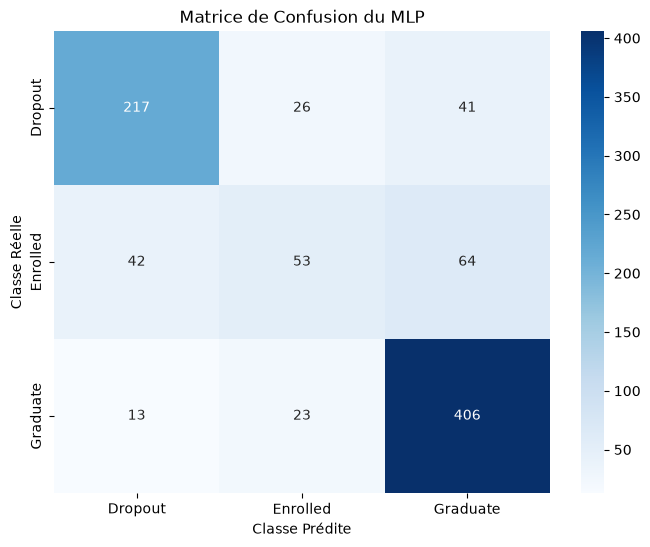


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.80      0.76      0.78       284
    Enrolled       0.52      0.33      0.41       159
    Graduate       0.79      0.92      0.85       442

    accuracy                           0.76       885
   macro avg       0.70      0.67      0.68       885
weighted avg       0.75      0.76      0.75       885



In [48]:
get_confusion_matrix(model_bn, X_test_pca, y_test)

La Batch Normalization (BN) modifie subtilement la dynamique d'apprentissage.
- Accuracy : 0.7638 (~76.4%). C'est un excellent score, le réseau converge de manière très propre et stable.
- Classe Enrolled : La Batch Normalization « durcit » un peu la frontière de décision. Elle élimine les faux positifs (d'où une bonne précision), mais du coup, elle rate un peu plus d'étudiants de cette classe minoritaire (rappel plus faible).

Comme la normalisation réduit la variance entre les exemples d'un même batch, elle peut parfois uniformiser un peu trop les décisions du réseau, ce qui pénalise le rappel sur la classe minoritaire (Enrolled), qui a justement besoin de nuances pour être détectée.

In [105]:
# Appel de la fonction
save_model(
    model=model_bn, 
    model_nom="mlp_model_bn"
)

Modèle 'mlp_model_bn' sauvegardé avec succès (PCA déjà existante) !


<hr style="width: 50%; margin: 12px auto 0px auto;" />

## 5.  Choix d'hyperparemeters

 
- Le choix d'hyperparamètres
    - Le choix de l'optimiseur : Comparer Adam (souvent par défaut et très efficace) avec d'autres choix comme RMSprop ou SGD (Descente de gradient stochastique) couplé à du Momentum.
    - Le taux d'apprentissage (Learning Rate - LR) : C'est souvent l'hyper-paramètre le plus critique. S'il est trop haut, l'apprentissage diverge ; s'il est trop bas, le modèle stagne. (Valeurs courantes : 0.001, 0.0005, 0.0001).
    - Le taux de Dropout : Ajuster la proportion de neurones désactivés aléatoirement à chaque étape (ex: passer de 0.3 à 0.4 ou 0.5 sur les couches denses).
    - La régularisation des poids (L1 / L2) : Jouer sur la pénalité de coût (comme le kernel_regularizer=l2(0.001)) pour forcer les poids du réseau à rester de petites valeurs et limiter la sur-mémorisation.
    - La taille des batchs (Batch Size) : Modifier le nombre d'exemples vus avant chaque mise à jour des poids (ex: 16, 32, 64, 128). Des batchs plus petits introduisent du bruit bénéfique pour la généralisation, tandis que des batchs plus grands accélèrent le calcul par époque.


- En amont (Prétraitement et Données)
    - Le nombre de composantes de la PCA : Tu as fixé la PCA à 30 dimensions (retenant 95% de la variance). Tu pourrais tester d'ajuster ce nombre (ex: 20 ou 40) pour voir si cela impacte la performance de classification, en particulier sur la classe Enrolled.